### Log grafikleri: loss ve HellaSwag-TR

Karpathy'nin [build-nanogpt](https://github.com/karpathy/build-nanogpt) reposundaki `play.ipynb` log grafiği hücresinin Türkçe veriye uyarlanmış hali. `train_gpt2.py` her 100 adımda `log/log.txt` dosyasına `adım train|val|hella değer` satırları yazıyor. Bu hücre o dosyayı okuyup grafikleri çiziyor.

Karpathy'nin referans değerleri İngilizce veriye ait olduğu için Türkçe veride geçerli değil. Aşağıdaki değerler yeniden ölçüldü:

| Çizgi | Değer | Not |
|---|---|---|
| OpenAI GPT-2 124M val loss | 4.6673 (B=4, T=256), 4.1691 (B=64, T=1024) | `dataset_val_000000.npy` üzerinde, val döngüsüyle aynı 20 adım. Tokenizer aynı, doğrudan karşılaştırılabilir |
| OpenAI GPT-2 124M HellaSwag-TR | 0.2750 | İngilizce eğitilmiş, Türkçede rastgeleye yakın |
| ytu-ce-cosmos/turkish-gpt2 HellaSwag-TR | 0.3112 | GPT-2 124M ile aynı mimari, Türkçe eğitilmiş. Kendi tokenizer'ı Türkçede karakter başına 2,5 kat daha az token harcıyor |
| Rastgele | 0.25 | 4 şıktan biri |


Min Train Loss: 1.627843
Min Validation Loss: 2.1427
Max Hellaswag eval: 0.259


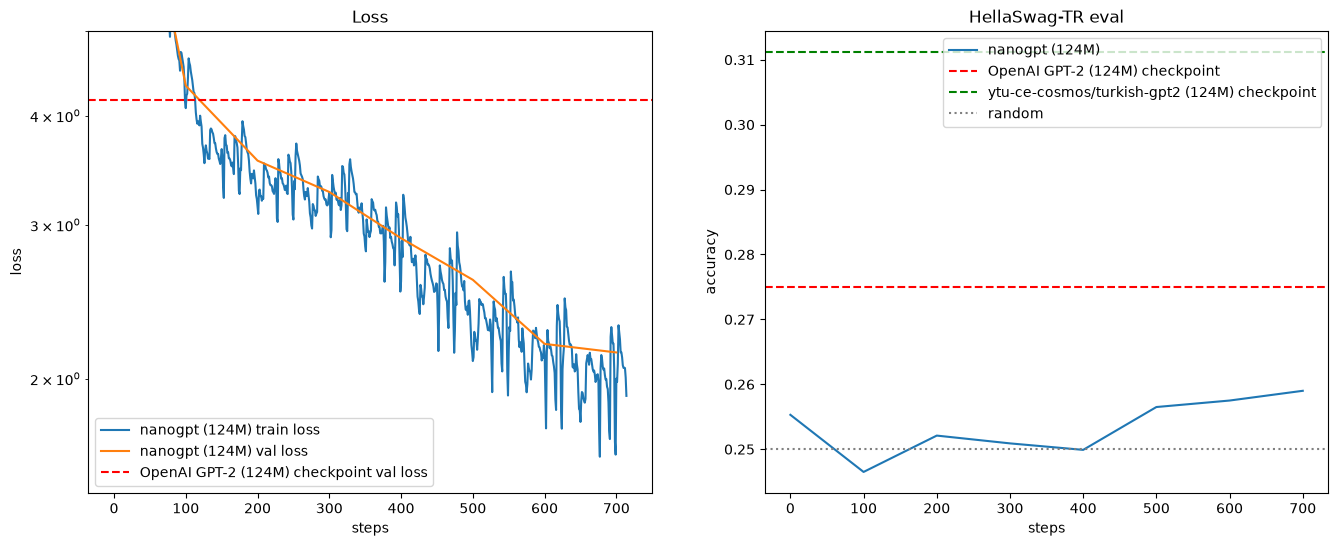

In [2]:
# parse and visualize the logfile
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

sz = "124M"
B, T = 64, 1024 # train_gpt2.py'deki B ve T ile aynı olmalı, val loss bu pencerelerle hesaplanıyor

# OpenAI GPT-2'nin bizim Türkçe val shard'ımızdaki loss'u (Karpathy'deki 3.2924 İngilizce FineWeb-Edu'ya ait)
loss_baseline = {
    (4, 256): 4.6673,
    (64, 1024): 4.1691,
}.get((B, T)) # başka bir B, T için None döner ve çizgi çizilmez
hella2_baseline = { # HellaSwag-TR for OpenAI GPT-2 (İngilizce eğitilmiş)
    "124M": 0.2750,
}[sz]
hella_tr_baseline = { # HellaSwag-TR for ytu-ce-cosmos/turkish-gpt2 (Türkçe eğitilmiş, GPT-3 çizgisinin yerine)
    "124M": 0.3112,
}[sz]
hella_random = 0.25 # 4 şıktan rastgele seçim

# load the log file
with open("log/log.txt", "r") as f:
    lines = f.readlines()

# parse the individual lines, group by stream (train,val,hella)
streams = {}
for line in lines:
    step, stream, val = line.strip().split()
    if stream not in streams:
        streams[stream] = {}
    streams[stream][int(step)] = float(val)

# convert each stream from {step: val} to (steps[], vals[])
# so it's easier for plotting
streams_xy = {}
for k, v in streams.items():
    # get all (step, val) items, sort them
    xy = sorted(list(v.items()))
    # unpack the list of tuples to tuple of lists
    streams_xy[k] = list(zip(*xy))

# create figure
plt.figure(figsize=(16, 6))

# Panel 1: losses: both train and val
plt.subplot(121)
xs, ys = streams_xy["train"] # training loss
ys = np.array(ys)
plt.plot(xs, ys, label=f'nanogpt ({sz}) train loss')
print("Min Train Loss:", min(ys))
xs, ys = streams_xy["val"] # validation loss
plt.plot(xs, ys, label=f'nanogpt ({sz}) val loss')
# horizontal line at GPT-2 baseline
if loss_baseline is not None:
    plt.axhline(y=loss_baseline, color='r', linestyle='--', label=f"OpenAI GPT-2 ({sz}) checkpoint val loss")
plt.xlabel("steps")
plt.ylabel("loss")
plt.yscale('log')
plt.ylim(top=5.0) # Karpathy 4.0 kullanıyor, Türkçede GPT-2 çizgisi 4'ün üstünde kalıyor
plt.legend()
plt.title("Loss")
print("Min Validation Loss:", min(ys))

# Panel 2: HellaSwag eval
plt.subplot(122)
xs, ys = streams_xy["hella"] # HellaSwag eval
ys = np.array(ys)
plt.plot(xs, ys, label=f"nanogpt ({sz})")
# horizontal line at GPT-2 baseline
if hella2_baseline:
    plt.axhline(y=hella2_baseline, color='r', linestyle='--', label=f"OpenAI GPT-2 ({sz}) checkpoint")
if hella_tr_baseline:
    plt.axhline(y=hella_tr_baseline, color='g', linestyle='--', label=f"ytu-ce-cosmos/turkish-gpt2 ({sz}) checkpoint")
plt.axhline(y=hella_random, color='gray', linestyle=':', label="random")
plt.xlabel("steps")
plt.ylabel("accuracy")
plt.legend()
plt.title("HellaSwag-TR eval")
print("Max Hellaswag eval:", max(ys))

### İngilizce model: GPT-2 ve GPT-3 ile karşılaştırma

Karpathy'nin orijinal grafiği: İngilizce eğitilmiş modelin log'u, İngilizce referans değerleriyle çiziliyor. Hücredeki `log_path` değişkenine İngilizce modelin log dosyasının yolunu yaz.

| Çizgi | Değer | Nerede ölçüldü |
|---|---|---|
| OpenAI GPT-2 124M val loss | 3.2924 | FineWeb-Edu val (B=64, T=1024, 20 adım) |
| OpenAI GPT-2 124M HellaSwag | 0.2945 | Orijinal İngilizce HellaSwag |
| OpenAI GPT-3 124M HellaSwag | 0.337 | Orijinal İngilizce HellaSwag (GPT-3 makalesi) |

Karşılaştırmanın doğru olması için modelin val loss'u FineWeb-Edu val shard'ında, HellaSwag sonucu da orijinal İngilizce HellaSwag'de ölçülmüş olmalı.

Min Train Loss: 4.142541
Min Validation Loss: 4.4806
Max Hellaswag eval: 0.2496


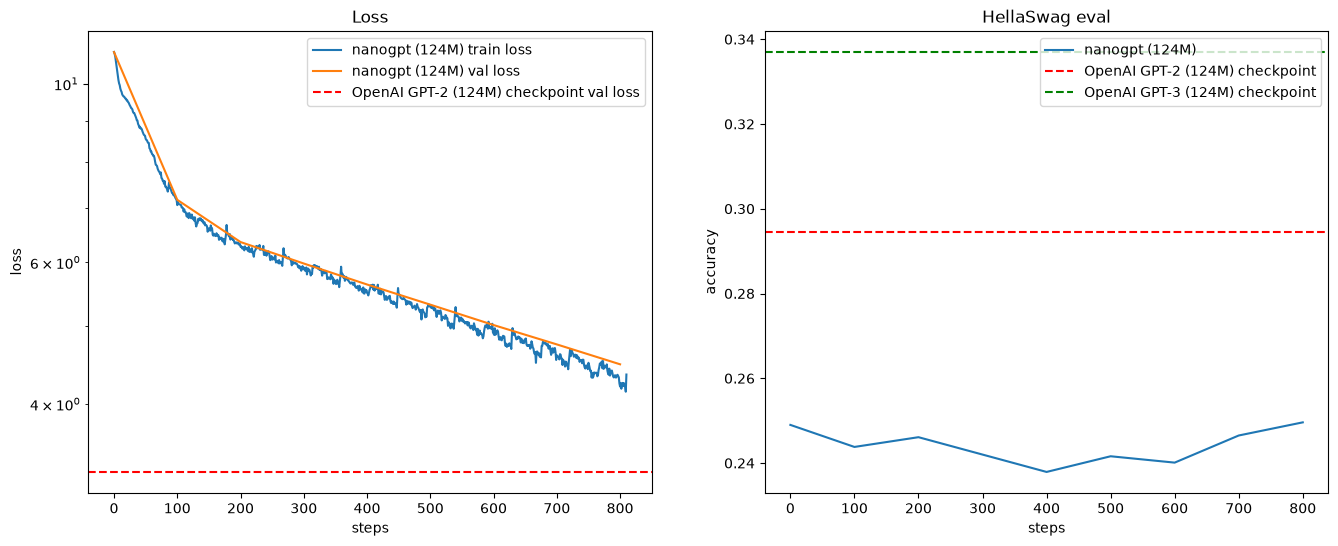

In [7]:
# parse and visualize the logfile, İngilizce eğitilmiş model + İngilizce GPT-2 / GPT-3 referansları
# bu hücre tek başına çalışır, üstteki hücreyi çalıştırmaya gerek yok
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

sz = "124M"
log_path = "log/log.txt" # İngilizce modelin log dosyası, başka bir yerdeyse burayı değiştir

# Karpathy'nin play.ipynb'deki orijinal değerleri (İngilizce veride ölçülmüş)
loss_baseline_en = { # OpenAI GPT-2 val loss, FineWeb-Edu val
    "124M": 3.2924,
}[sz]
hella2_baseline_en = { # HellaSwag for GPT-2
    "124M": 0.294463,
    "350M": 0.375224,
    "774M": 0.431986,
    "1558M": 0.488946,
}[sz]
hella3_baseline_en = { # HellaSwag for GPT-3
    "124M": 0.337,
    "350M": 0.436,
    "774M": 0.510,
    "1558M": 0.547,
}[sz]

# load the log file
with open(log_path, "r") as f:
    lines = f.readlines()

# parse the individual lines, group by stream (train,val,hella)
streams = {}
for line in lines:
    step, stream, val = line.strip().split()
    if stream not in streams:
        streams[stream] = {}
    streams[stream][int(step)] = float(val)

# convert each stream from {step: val} to (steps[], vals[])
# so it's easier for plotting
streams_xy = {}
for k, v in streams.items():
    # get all (step, val) items, sort them
    xy = sorted(list(v.items()))
    # unpack the list of tuples to tuple of lists
    streams_xy[k] = list(zip(*xy))

# create figure
plt.figure(figsize=(16, 6))

# Panel 1: losses: both train and val
plt.subplot(121)
xs, ys = streams_xy["train"] # training loss
ys = np.array(ys)
plt.plot(xs, ys, label=f'nanogpt ({sz}) train loss')
print("Min Train Loss:", min(ys))
xs, ys = streams_xy["val"] # validation loss
plt.plot(xs, ys, label=f'nanogpt ({sz}) val loss')
# horizontal line at GPT-2 baseline
if loss_baseline_en is not None:
    plt.axhline(y=loss_baseline_en, color='r', linestyle='--', label=f"OpenAI GPT-2 ({sz}) checkpoint val loss")
plt.xlabel("steps")
plt.ylabel("loss")
plt.yscale('log')
# Karpathy burada plt.ylim(top=4.0) kullanıyor, ama loss henüz 4'ün altına inmediyse eğriler grafiğin dışında kalıyor
plt.legend()
plt.title("Loss")
print("Min Validation Loss:", min(ys))

# Panel 2: HellaSwag eval
plt.subplot(122)
xs, ys = streams_xy["hella"] # HellaSwag eval
ys = np.array(ys)
plt.plot(xs, ys, label=f"nanogpt ({sz})")
# horizontal line at GPT-2 baseline
if hella2_baseline_en:
    plt.axhline(y=hella2_baseline_en, color='r', linestyle='--', label=f"OpenAI GPT-2 ({sz}) checkpoint")
if hella3_baseline_en:
    plt.axhline(y=hella3_baseline_en, color='g', linestyle='--', label=f"OpenAI GPT-3 ({sz}) checkpoint")
plt.xlabel("steps")
plt.ylabel("accuracy")
plt.legend()
plt.title("HellaSwag eval")
print("Max Hellaswag eval:", max(ys))